# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
%pip install plotly pandas numpy


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())


Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [3]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


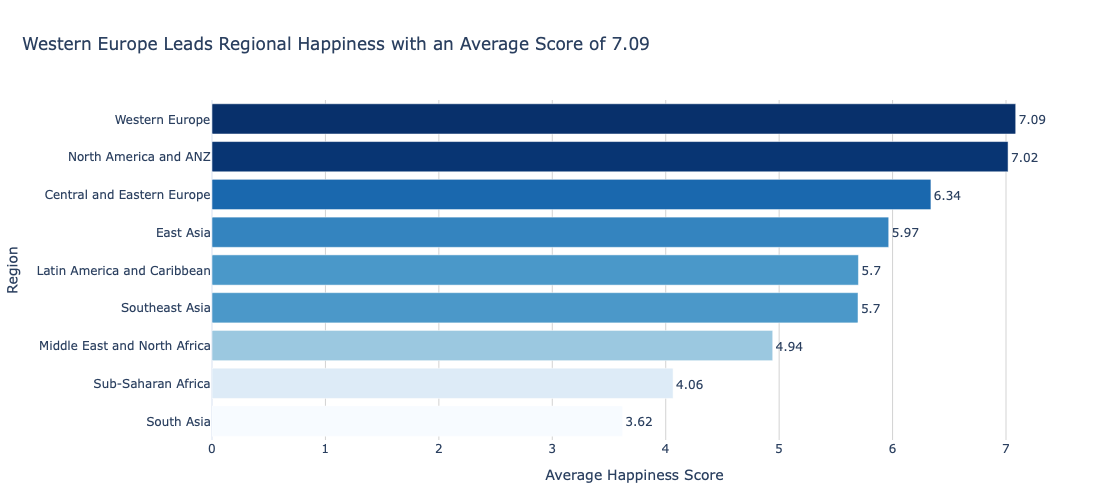

In [4]:

# Task 1: Regional comparison bar chart

import plotly.express as px

# Calculate average happiness by region
region_avg = (
    df.groupby('Region', as_index=False)['Happiness_Score']
    .mean()
    .sort_values('Happiness_Score', ascending=True)
)

# Identify the highest-scoring region for the title
highest_region = region_avg.iloc[-1]['Region']
highest_score = region_avg.iloc[-1]['Happiness_Score']

# Create chart
fig1 = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    text=region_avg['Happiness_Score'].round(2),
    color='Happiness_Score',
    color_continuous_scale='Blues',
    title=(
        f"{highest_region} Leads Regional Happiness "
        f"with an Average Score of {highest_score:.2f}"
    ),
    labels={
        'Happiness_Score': 'Average Happiness Score',
        'Region': 'Region'
    }
)

fig1.update_traces(
    textposition='outside',
    cliponaxis=False,
    hovertemplate='%{y}<br>Average score: %{x:.2f}<extra></extra>'
)

fig1.update_layout(
    template='plotly_white',
    title_x=0.02,
    xaxis=dict(
        rangemode='tozero',
        showgrid=True,
        gridcolor='lightgray'
    ),
    yaxis=dict(
        categoryorder='array',
        categoryarray=region_avg['Region'].tolist()
    ),
    coloraxis_showscale=False,
    margin=dict(l=140, r=50, t=100, b=60),
    height=500
)

fig1.show()


---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


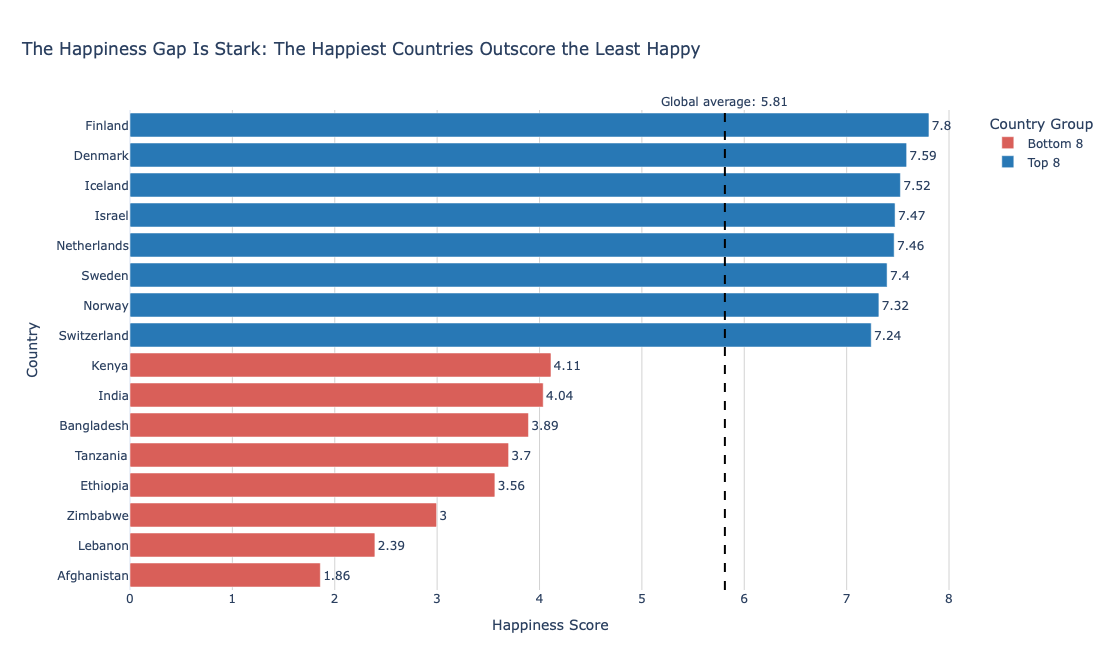

In [5]:

# Task 2: Top 8 vs. Bottom 8 contrast

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Get the happiest and least happy countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

# Combine and sort countries
combined = pd.concat([bottom8, top8])
combined = combined.sort_values('Happiness_Score', ascending=True)

# Calculate global average
global_avg = df['Happiness_Score'].mean()

# Create chart
fig2 = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Top 8': '#2878B5',
        'Bottom 8': '#D95F59'
    },
    text=combined['Happiness_Score'].round(2),
    title=(
        "The Happiness Gap Is Stark: "
        "The Happiest Countries Outscore the Least Happy"
    ),
    labels={
        'Happiness_Score': 'Happiness Score',
        'Country': 'Country',
        'Group': 'Country Group'
    }
)

fig2.update_traces(
    textposition='outside',
    cliponaxis=False,
    hovertemplate='%{y}<br>Score: %{x:.2f}<extra></extra>'
)

# Add global-average reference line
fig2.add_vline(
    x=global_avg,
    line_dash='dash',
    line_color='black',
    line_width=2,
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

fig2.update_layout(
    template='plotly_white',
    title_x=0.02,
    xaxis=dict(
        rangemode='tozero',
        showgrid=True,
        gridcolor='lightgray'
    ),
    yaxis=dict(
        categoryorder='array',
        categoryarray=combined['Country'].tolist()
    ),
    legend_title_text='Country Group',
    margin=dict(l=130, r=50, t=110, b=60),
    height=650
)

fig2.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


               Region        GDP   Freedom
0      Western Europe  10.963533  0.896067
1       Latin America        NaN       NaN
2           East Asia  10.312000  0.754000
3  Sub-Saharan Africa   7.082000  0.599429
4          South Asia   7.152250  0.546250


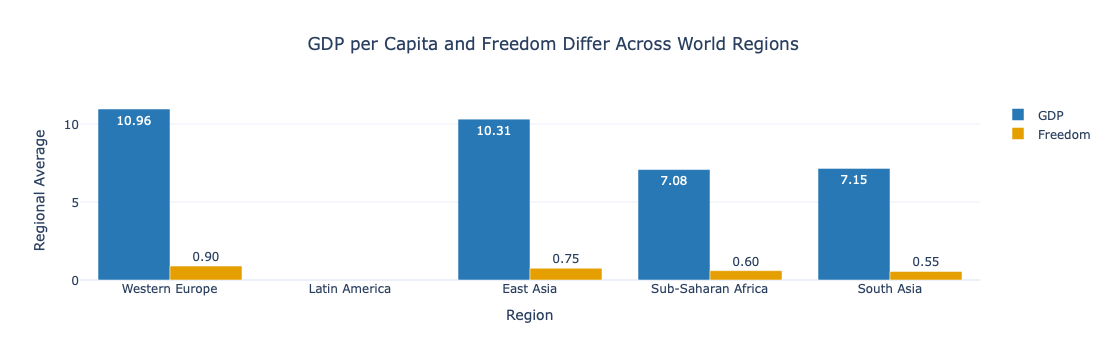

In [6]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE

# Task 3: GDP and Freedom across five regions

# Step 1: Select the five required regions
selected_regions = [
    'Western Europe',
    'Latin America',
    'East Asia',
    'Sub-Saharan Africa',
    'South Asia'
]

# Step 2: Filter the dataset and calculate regional averages
region_factors = (
    df[df['Region'].isin(selected_regions)]
    .groupby('Region')[['GDP', 'Freedom']]
    .mean()
    .reindex(selected_regions)
    .reset_index()
)

print(region_factors)

# Step 3: Reshape the data for a grouped bar chart
chart_data = region_factors.melt(
    id_vars='Region',
    value_vars=['GDP', 'Freedom'],
    var_name='Factor',
    value_name='Average Value'
)

# Step 4: Create the grouped bar chart
fig3 = px.bar(
    chart_data,
    x='Region',
    y='Average Value',
    color='Factor',
    barmode='group',
    color_discrete_map={
        'GDP': '#2878B5',
        'Freedom': '#E69F00'
    },
    title='GDP per Capita and Freedom Differ Across World Regions',
    labels={
        'Region': 'Region',
        'Average Value': 'Regional Average',
        'Factor': 'Indicator'
    },
    text_auto='.2f'
)

fig3.update_layout(
    template='plotly_white',
    yaxis=dict(rangemode='tozero', title='Regional Average'),
    xaxis_title='Region',
    title_x=0.5,
    font=dict(size=12),
    legend_title_text=''
)

fig3.show()